# 🎓 Student Performance Classification Project
**GDGoC Weekly Class - Machine Learning Track**

Welcome to this hands-on machine learning notebook! In this project, we will build an end-to-end classification pipeline to predict whether a student will **pass** or **fail** based on various academic and behavioral features (study hours, attendance rate, previous scores, assignment scores, and extracurricular participation).

### 📚 What You Will Learn:
1. **Synthetic Data Generation**: Creating realistic educational datasets using `pandas` and `numpy`.
2. **Exploratory Data Analysis (EDA)**: Visualizing data distributions and correlations using `matplotlib` and `seaborn`.
3. **Data Preprocessing & Splitting**: Preparing features, scaling, and splitting into train/test sets using `scikit-learn`.
4. **Model Training & Evaluation**: Training **Logistic Regression** and **Random Forest Classifier**, and evaluating them with accuracy, classification report, and confusion matrix.

---
## Step 1: Import Libraries & Setup
First, let's import all necessary Python libraries for data manipulation, visualization, and machine learning.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Styling for plots
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


---
## Step 2: Generate Synthetic Student Dataset
Since we might not have a pre-existing CSV file ready, we'll generate a realistic synthetic dataset of 1,000 students using `numpy.random`.

### Features:
- `study_hours`: Weekly hours spent studying (2 - 25 hours)
- `attendance_rate`: Percentage of class attendance (50% - 100%)
- `previous_score`: Score from the previous semester (40 - 100)
- `assignment_score`: Average assignment score (50 - 100)
- `extracurricular`: Participation in extracurricular activities (0 = No, 1 = Yes)
- `pass_status`: Target variable (0 = Fail, 1 = Pass) determined by a weighted formula + random noise.

In [2]:
np.random.seed(42)
n_samples = 1000

# Generating features
study_hours = np.random.uniform(2.0, 25.0, n_samples)
attendance_rate = np.random.uniform(50.0, 100.0, n_samples)
previous_score = np.random.normal(70.0, 12.0, n_samples).clip(40, 100)
assignment_score = np.random.normal(75.0, 10.0, n_samples).clip(50, 100)
extracurricular = np.random.choice([0, 1], size=n_samples, p=[0.4, 0.6])

# Calculating a success probability score based on features + noise
score_formula = (
    (study_hours * 1.5) +
    (attendance_rate * 0.4) +
    (previous_score * 0.3) +
    (assignment_score * 0.4) +
    (extracurricular * 3.0) +
    np.random.normal(0, 5, n_samples)
)

# Thresholding to determine pass (1) or fail (0)
pass_status = (score_formula > 105).astype(int)

# Creating DataFrame
df = pd.DataFrame({
    'study_hours': study_hours,
    'attendance_rate': attendance_rate,
    'previous_score': previous_score,
    'assignment_score': assignment_score,
    'extracurricular': extracurricular,
    'pass_status': pass_status
})

# Display first 5 rows
print(f"Dataset Shape: {df.shape}")
display(df.head())
print("\nClass Distribution:")
print(df['pass_status'].value_counts(normalize=True))

Dataset Shape: (1000, 6)


,study_hours,attendance_rate,previous_score,assignment_score,extracurricular,pass_status
0,10.614423,59.256646,59.464209,93.709652,1,0
1,23.866429,77.095047,60.077436,78.896142,1,1
2,18.835861,93.647292,67.282253,66.317073,0,1
3,15.769145,86.611244,74.408386,80.346291,0,0
4,5.588429,90.328057,80.963016,50.000000,1,0



Class Distribution:
pass_status
0    0.557
1    0.443
Name: proportion, dtype: float64


---
## Step 3: Exploratory Data Analysis (EDA)
Let's explore our dataset to understand feature distributions and correlations.

In [3]:
# Statistical summary
display(df.describe())

,study_hours,attendance_rate,previous_score,assignment_score,extracurricular,pass_status
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,13.275901,75.350865,70.136085,75.024577,0.588000,0.443000
std,6.719159,14.609495,11.563324,10.110746,0.492441,0.496989
min,2.106537,50.160913,40.000000,50.000000,0.000000,0.000000
25%,7.427385,62.053714,62.241329,67.929241,0.000000,0.000000
50%,13.426570,75.936695,70.010401,74.986412,1.000000,0.000000
75%,19.119351,88.023253,78.071747,81.815370,1.000000,1.000000
max,24.993506,99.970686,100.000000,100.000000,1.000000,1.000000


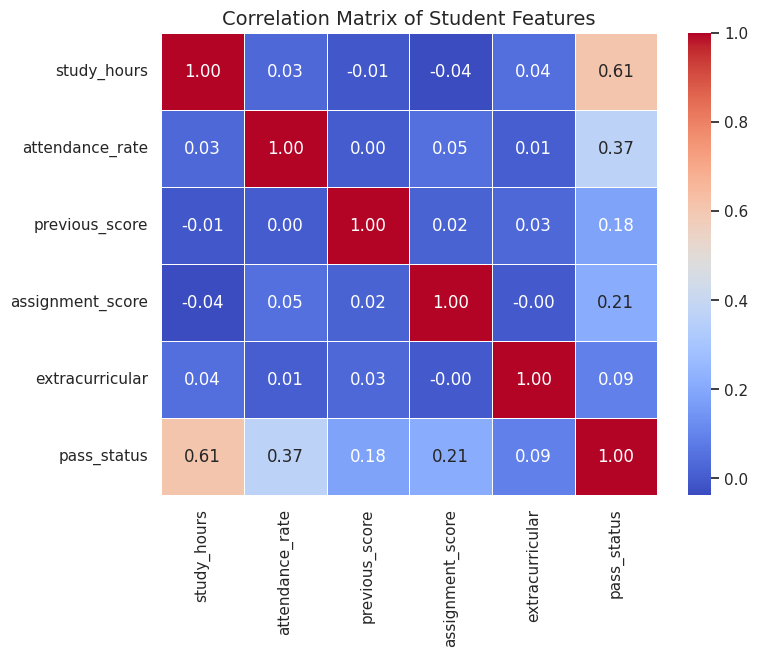

In [4]:
# 1. Correlation Heatmap
plt.figure(figsize=(8, 6))
correlation = df.corr()
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Student Features', fontsize=14)
plt.show()

/tmp/ipykernel_1917/14969239.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='pass_status', y='study_hours', data=df, palette='Set2')


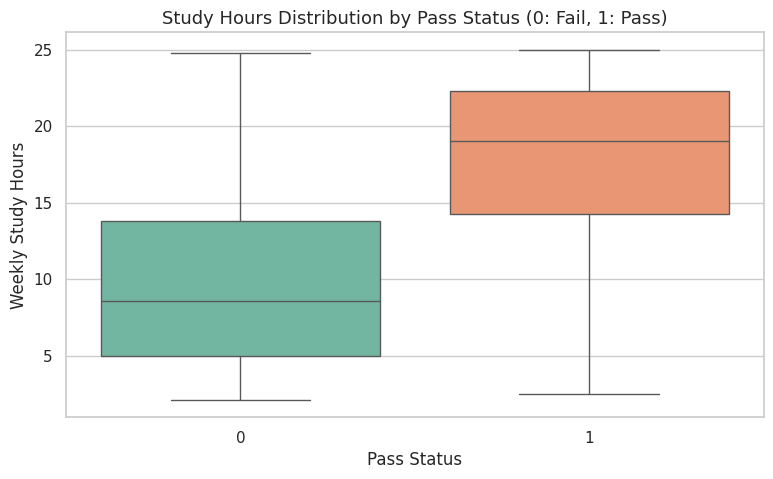

In [5]:
# 2. Study Hours vs Pass Status
plt.figure(figsize=(9, 5))
sns.boxplot(x='pass_status', y='study_hours', data=df, palette='Set2')
plt.title('Study Hours Distribution by Pass Status (0: Fail, 1: Pass)', fontsize=13)
plt.xlabel('Pass Status')
plt.ylabel('Weekly Study Hours')
plt.show()

---
## Step 4: Data Preprocessing & Train-Test Split
Now we separate our feature matrix ($X$) from our target vector ($y$), split the data into training and testing sets (80% train, 20% test), and apply feature scaling using `StandardScaler`.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separate features and target
X = df.drop(columns=['pass_status'])
y = df['pass_status']

# Train-Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (800, 5)
Testing set shape: (200, 5)


---
## Step 5: Model 1 - Logistic Regression
Logistic Regression is a foundational linear classification algorithm. Let's train it and evaluate its performance.

Logistic Regression Accuracy: 86.50%

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.86      0.88       111
           1       0.83      0.88      0.85        89

    accuracy                           0.86       200
   macro avg       0.86      0.87      0.86       200
weighted avg       0.87      0.86      0.87       200



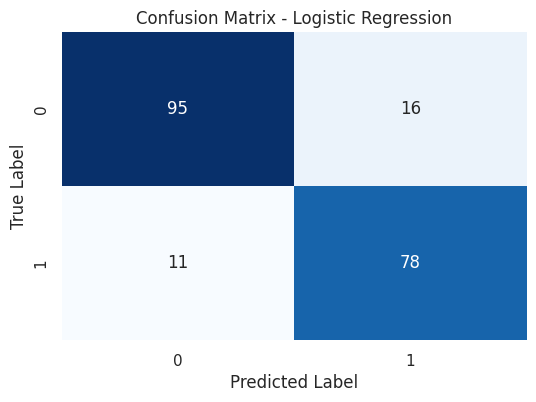

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Initialize and train Logistic Regression
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train_scaled, y_train)

# Predictions
y_pred_lr = log_reg.predict(X_test_scaled)

# Evaluation
acc_lr = accuracy_score(y_test, y_pred_lr)
print(f"Logistic Regression Accuracy: {acc_lr * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

# Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_lr), annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

---
## Step 6: Model 2 - Random Forest Classifier
Random Forest is an ensemble learning method that builds multiple decision trees and merges them together to get a more accurate and stable prediction.

Random Forest Accuracy: 88.50%

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.87      0.89       111
           1       0.85      0.90      0.87        89

    accuracy                           0.89       200
   macro avg       0.88      0.89      0.88       200
weighted avg       0.89      0.89      0.89       200



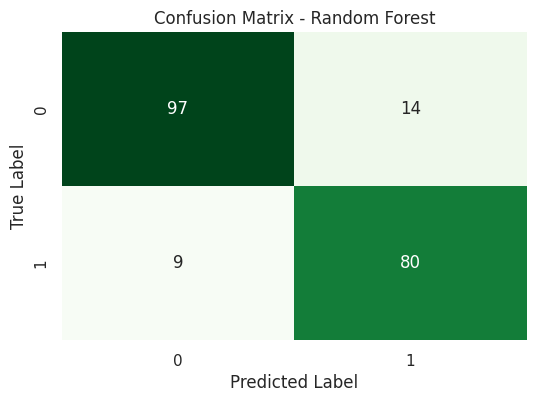

In [8]:
from sklearn.ensemble import RandomForestClassifier

# Initialize and train Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Predictions
y_pred_rf = rf_model.predict(X_test)

# Evaluation
acc_rf = accuracy_score(y_test, y_pred_rf)
print(f"Random Forest Accuracy: {acc_rf * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

# Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Greens', cbar=False)
plt.title('Confusion Matrix - Random Forest')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

---
## Step 7: Feature Importance Analysis (Random Forest)
Let's check which features contribute the most to predicting student performance.

/tmp/ipykernel_1917/1145519494.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feature_importances.values, y=feature_importances.index, palette='viridis')


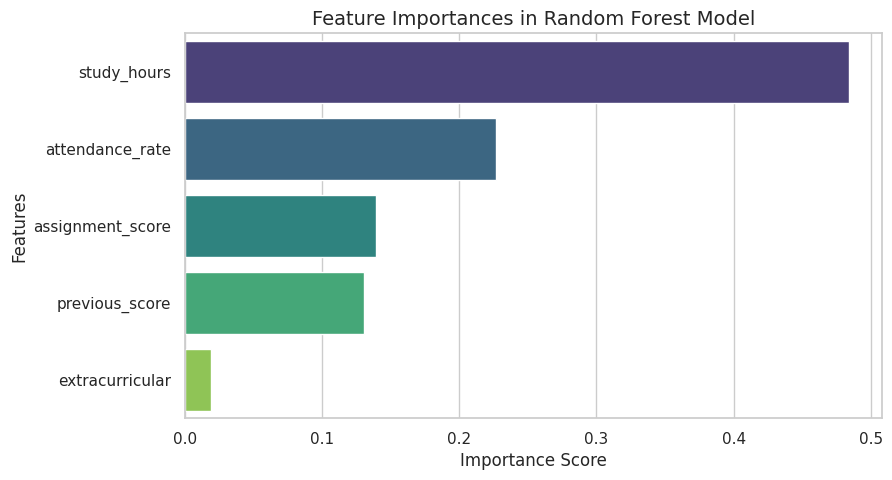

In [9]:
feature_importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(x=feature_importances.values, y=feature_importances.index, palette='viridis')
plt.title('Feature Importances in Random Forest Model', fontsize=14)
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

---
## Step 8: Model Comparison & Conclusion
Let's compare both models side-by-side to see which one performs better for our dataset.

,Model,Accuracy (%)
0,Logistic Regression,86.5
1,Random Forest,88.5


/tmp/ipykernel_1917/171368477.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='Accuracy (%)', data=comparison_df, palette='magma')


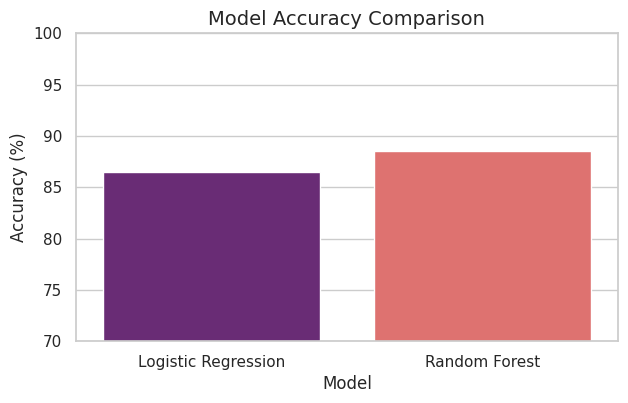

In [10]:
comparison_df = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy (%)': [acc_lr * 100, acc_rf * 100]
})

display(comparison_df)

plt.figure(figsize=(7, 4))
sns.barplot(x='Model', y='Accuracy (%)', data=comparison_df, palette='magma')
plt.ylim(70, 100)
plt.title('Model Accuracy Comparison', fontsize=14)
plt.ylabel('Accuracy (%)')
plt.show()